# 사출성형 품질 예측 — 결과 검증 노트북

이 노트북은 **저장된 모델 예측 결과를 다시 집계하고 시각화**합니다. 모델을 재학습하거나 새로운 시험 결과를 만들어내지 않습니다. `Tree_Models_Training.ipynb`는 별도로 제공되며, 해당 노트북의 전체 재실행에는 팀 공통 데이터 분할 자료가 필요합니다.

- 사용 데이터: `results/metrics.csv`, `results/tree_predictions.csv`
- 테스트 표본: 모델당 291개
- 모델: DecisionTree, RandomForest, ExtraTrees
- 결과 해석: 학습 내부 CV Macro F1과 최종 테스트 Accuracy는 서로 다른 지표임


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

BASE = Path.cwd()
assert (BASE/'results'/'metrics.csv').exists(), '이 노트북은 injection-quality-tree-models 폴더에서 실행해 주세요.'
metrics = pd.read_csv(BASE/'results'/'metrics.csv')
pred = pd.read_csv(BASE/'results'/'tree_predictions.csv')
print(metrics[['model','cv_macro_f1_mean_tuned_selection','test_accuracy','test_macro_f1','false_acceptance_count']].round(4).to_string(index=False))

       model  cv_macro_f1_mean_tuned_selection  test_accuracy  test_macro_f1  false_acceptance_count
DecisionTree                            0.9241         0.9072         0.9063                       4
RandomForest                            0.9469         0.9381         0.9365                       5
  ExtraTrees                            0.9502         0.9313         0.9300                       7


## 저장된 테스트 예측으로 점수 재계산

모든 모델을 동일한 291개 표본에서 평가합니다. 이 계산은 **저장된 예측 파일**과 보고 지표의 일치 여부를 확인합니다. 원본 데이터 전처리와 학습 자체를 재현하는 검사는 아닙니다.

In [2]:
for model, group in pred.groupby('model',sort=False):
    report = metrics.loc[metrics.model==model].iloc[0]
    acc = accuracy_score(group.y_true,group.y_pred)
    f1 = f1_score(group.y_true,group.y_pred,average='macro',zero_division=0)
    missed = int(((group.y_true==1)&(group.y_pred!=1)).sum())
    assert len(group)==291
    assert abs(acc-report.test_accuracy)<1e-10
    assert abs(f1-report.test_macro_f1)<1e-10
    assert missed==int(report.false_acceptance_count)
    print(f'{model}: N={len(group)}, Test Accuracy={acc:.4f}, Macro F1={f1:.4f}, Waste 누락={missed}')

DecisionTree: N=291, Test Accuracy=0.9072, Macro F1=0.9063, Waste 누락=4
RandomForest: N=291, Test Accuracy=0.9381, Macro F1=0.9365, Waste 누락=5
ExtraTrees: N=291, Test Accuracy=0.9313, Macro F1=0.9300, Waste 누락=7


## 성능 비교

최종 테스트를 보고 대표 모델을 사후에 변경하지 않았으며, CV 및 Test는 별도 지표로 나란히 나타냅니다.

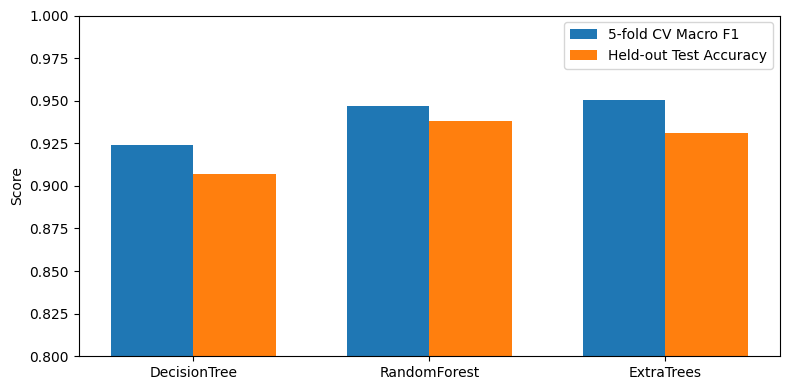

In [3]:
fig, ax = plt.subplots(figsize=(8,4))
xx=range(len(metrics)); width=0.35
ax.bar([v-width/2 for v in xx],metrics.cv_macro_f1_mean_tuned_selection,width,label='5-fold CV Macro F1')
ax.bar([v+width/2 for v in xx],metrics.test_accuracy,width,label='Held-out Test Accuracy')
ax.set_xticks(list(xx),metrics.model)
ax.set_ylim(.80,1.0); ax.set_ylabel('Score'); ax.legend()
plt.tight_layout(); plt.show()

## 혼동행렬 및 오류 유형

품질 등급: 1 Waste, 2 Acceptable, 3 Target, 4 Inefficient. 불량 제품을 정상으로 놓친 수는 `Waste 누락`으로 집계했습니다.

In [4]:
for model, group in pred.groupby('model',sort=False):
    cm=confusion_matrix(group.y_true,group.y_pred,labels=[1,2,3,4])
    print(model)
    print(pd.DataFrame(cm,index=['true_Waste','true_Acceptable','true_Target','true_Inefficient'],columns=['pred_Waste','pred_Acceptable','pred_Target','pred_Inefficient']).to_string())
    print()

DecisionTree
                  pred_Waste  pred_Acceptable  pred_Target  pred_Inefficient
true_Waste                70                4            0                 0
true_Acceptable            9               72            1                 0
true_Target                0                0           55                 7
true_Inefficient           0                0            6                67

RandomForest
                  pred_Waste  pred_Acceptable  pred_Target  pred_Inefficient
true_Waste                69                5            0                 0
true_Acceptable            2               79            1                 0
true_Target                0                0           55                 7
true_Inefficient           0                0            3                70

ExtraTrees
                  pred_Waste  pred_Acceptable  pred_Target  pred_Inefficient
true_Waste                67                7            0                 0
true_Acceptable            2         

## 검증 범위와 한계

- **재확인 가능:** 저장된 `y_true`/`y_pred`의 291개 샘플 기준 Test Accuracy, Macro F1, Waste 누락 수
- **원본 재현에는 추가 자료 필요:** 공통 학습·시험 분할 ZIP과 공개 원본 CSV
- **미검증:** 새로운 생산일자·설비·금형 등 외부 데이터에 대한 일반화, 실공정 적용 성능
- **공정변수 중요도:** 모델 예측에 사용한 정보의 상대적 기여를 뜻하며 인과적 공정 개선 효과는 보장하지 않음
